In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os, time

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

from sklearn.metrics import (
    roc_auc_score, accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, f1_score
)

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

RANDOM_STATE = 42

In [2]:
train = pd.read_csv('data/train.csv')
train = train.drop(columns=['id'])
print(f'Train shape: {train.shape}')
train.head()

Train shape: (668665, 14)


,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [3]:

train['Will_Buy_EV'] = train['Will_Buy_EV'].map({'Yes': 1, 'No': 0})

binary_cols = ['Home_Charging_Possible', 'Subsidy_Available']
for col in binary_cols:
    train[col] = train[col].map({'Yes': 1, 'No': 0})

print('Binary encod')

Binary encod


In [4]:

range_anxiety_map = {'Low': 0, 'Medium': 1, 'High': 2}
train['Range_Anxiety_Level'] = train['Range_Anxiety_Level'].map(range_anxiety_map)

print('Label encodi')
print(f"Range_Anxiety_Level unique values: {train['Range_Anxiety_Level'].unique()}")

Label encodi
Range_Anxiety_Level unique values: [0 1 2]


In [5]:

nominal_cols = ['Gender', 'City_Type', 'Current_Car_Type']
train = pd.get_dummies(train, columns=nominal_cols, drop_first=False)

bool_cols = train.select_dtypes(include='bool').columns
train[bool_cols] = train[bool_cols].astype(int)

print(f'After one-hot encoding: {train.shape}')
train.head()

After one-hot encoding: (668665, 21)


,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,...,Gender_Female,Gender_Male,Gender_Other,City_Type_Rural,City_Type_Suburban,City_Type_Urban,Current_Car_Type_Hatchback,Current_Car_Type_SUV,Current_Car_Type_Sedan,Current_Car_Type_Truck
0,66,92887.0,23.4,2,3,7,1.0,1,0,0,...,0,1,0,0,1,0,0,0,1,0
1,38,30000.0,5.0,1,2,2,4.0,1,0,0,...,0,1,0,1,0,0,0,1,0,0
2,26,94389.0,36.8,1,8,15,5.0,0,1,0,...,1,0,0,0,0,1,0,0,1,0
3,66,73580.0,23.7,2,6,9,3.0,1,0,0,...,0,1,0,0,1,0,1,0,0,0
4,54,57898.0,50.8,1,2,3,3.0,1,0,0,...,0,1,0,0,1,0,1,0,0,0


In [6]:

assert train.select_dtypes(include='object').shape[1] == 0, 'Still have object columns!'
print('All features are numeric')
print(f'Columns ({train.shape[1]}): {list(train.columns)}')

All features are numeric
Columns (21): ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level', 'Will_Buy_EV', 'Gender_Female', 'Gender_Male', 'Gender_Other', 'City_Type_Rural', 'City_Type_Suburban', 'City_Type_Urban', 'Current_Car_Type_Hatchback', 'Current_Car_Type_SUV', 'Current_Car_Type_Sedan', 'Current_Car_Type_Truck']


In [7]:
X = train.drop(columns=['Will_Buy_EV'])
y = train['Will_Buy_EV']

feature_cols = list(X.columns)
joblib.dump(feature_cols, 'models/feature_columns.pkl')

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
)

print(f'X_train: {X_train.shape}  |  X_val: {X_val.shape}')
print(f'y_train distribution:\n{y_train.value_counts(normalize=True).round(4)}')

X_train: (468065, 20)  |  X_val: (200600, 20)
y_train distribution:
Will_Buy_EV
0    0.8254
1    0.1746
Name: proportion, dtype: float64


In [8]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val) 

os.makedirs('models', exist_ok=True)
joblib.dump(scaler, 'models/scaler.pkl')
print('Scaler szaved')

Scaler szaved


In [9]:

results = {}  

def evaluate(name, model, X_t, y_t, X_v, y_v, save=True):
    """Fit model, evaluate, print metrics, store in results dict."""
    start = time.time()
    model.fit(X_t, y_t)
    elapsed = time.time() - start
    
    y_pred = model.predict(X_v)
    y_proba = model.predict_proba(X_v)[:, 1]
    
    acc = accuracy_score(y_v, y_pred)
    auc = roc_auc_score(y_v, y_proba)
    f1  = f1_score(y_v, y_pred)
    
    results[name] = {'Accuracy': acc, 'ROC_AUC': auc, 'F1_Score': f1, 'Time_s': elapsed}
    
    print(f'  {name}')

    print(f'  Accuracy : {acc:.4f}')
    print(f'  ROC-AUC  : {auc:.4f}')
    print(f'  F1-Score : {f1:.4f}')
    print(f'  Time     : {elapsed:.2f}s')
    print(f'\n{classification_report(y_v, y_pred)}')
    
    if save:
        joblib.dump(model, f'models/{name.lower().replace(" ", "_")}.pkl')
    
    return model

In [10]:
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr = evaluate('Logistic Regression', lr, X_train_scaled, y_train, X_val_scaled, y_val)

  Logistic Regression
  Accuracy : 0.8950
  ROC-AUC  : 0.9382
  F1-Score : 0.6870
  Time     : 0.42s

              precision    recall  f1-score   support

           0       0.93      0.94      0.94    165566
           1       0.72      0.66      0.69     35034

    accuracy                           0.90    200600
   macro avg       0.82      0.80      0.81    200600
weighted avg       0.89      0.90      0.89    200600



In [11]:
dt = DecisionTreeClassifier(max_depth=10, min_samples_split=20, random_state=RANDOM_STATE)
dt = evaluate('Decision Tree', dt, X_train, y_train, X_val, y_val)

  Decision Tree
  Accuracy : 0.8972
  ROC-AUC  : 0.9383
  F1-Score : 0.6929
  Time     : 2.14s

              precision    recall  f1-score   support

           0       0.93      0.95      0.94    165566
           1       0.72      0.66      0.69     35034

    accuracy                           0.90    200600
   macro avg       0.83      0.81      0.82    200600
weighted avg       0.89      0.90      0.90    200600



In [12]:
rf = RandomForestClassifier(n_estimators=300, max_depth=15, n_jobs=-1, random_state=RANDOM_STATE)
rf = evaluate('Random Forest', rf, X_train, y_train, X_val, y_val)

  Random Forest
  Accuracy : 0.8970
  ROC-AUC  : 0.9390
  F1-Score : 0.6858
  Time     : 30.80s

              precision    recall  f1-score   support

           0       0.93      0.95      0.94    165566
           1       0.73      0.64      0.69     35034

    accuracy                           0.90    200600
   macro avg       0.83      0.80      0.81    200600
weighted avg       0.89      0.90      0.89    200600



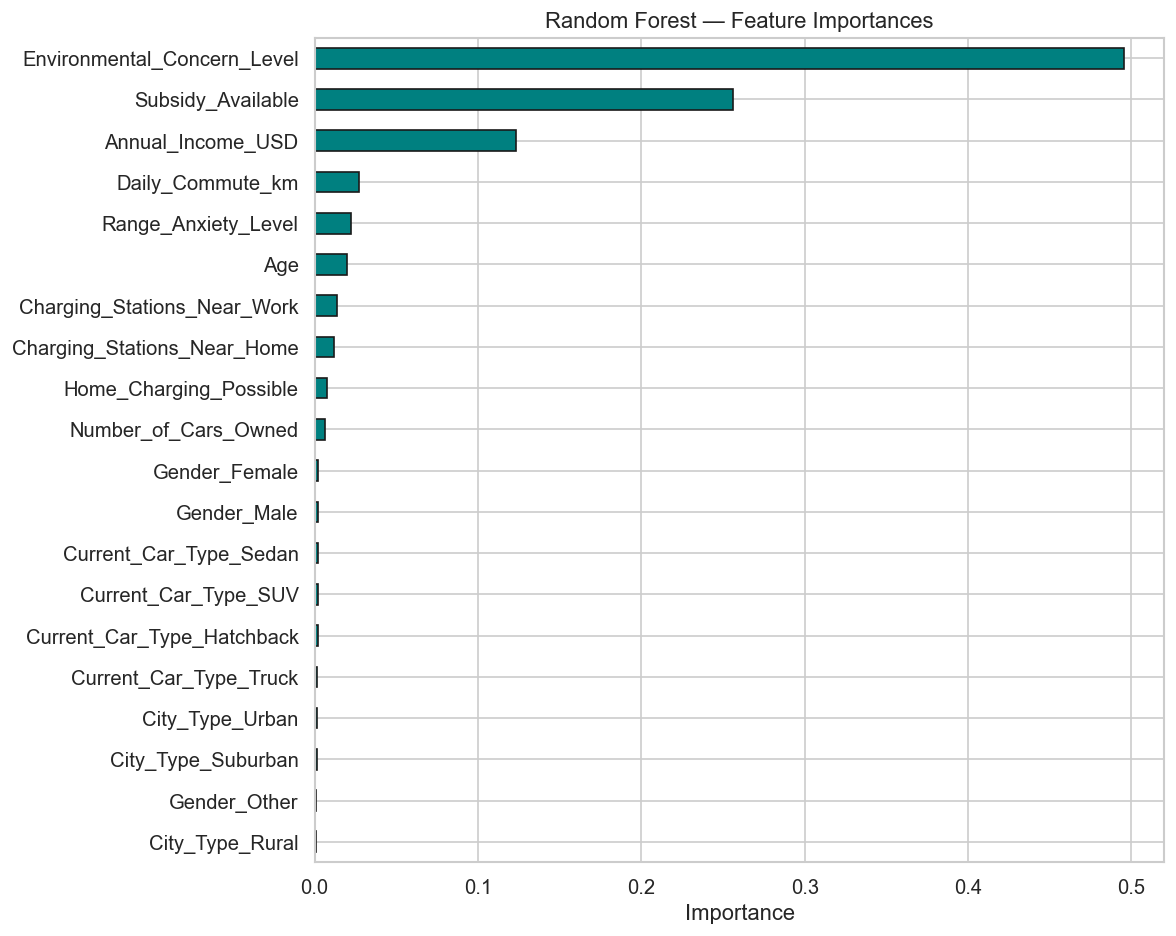

In [13]:

fi = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(10, 8))
fi.plot.barh(color='teal', edgecolor='k')
plt.title('Random Forest — Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [14]:
xgb_clf = xgb.XGBClassifier(
    n_estimators=500, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric='auc', n_jobs=-1, random_state=RANDOM_STATE,
    use_label_encoder=False
)
xgb_clf = evaluate('XGBoost', xgb_clf, X_train, y_train, X_val, y_val)

  XGBoost
  Accuracy : 0.8982
  ROC-AUC  : 0.9418
  F1-Score : 0.6982
  Time     : 9.50s

              precision    recall  f1-score   support

           0       0.93      0.95      0.94    165566
           1       0.72      0.67      0.70     35034

    accuracy                           0.90    200600
   macro avg       0.83      0.81      0.82    200600
weighted avg       0.90      0.90      0.90    200600



In [15]:
lgb_clf = lgb.LGBMClassifier(
    n_estimators=500, learning_rate=0.05, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8,
    random_state=RANDOM_STATE, verbose=-1
)
lgb_clf = evaluate('LightGBM', lgb_clf, X_train, y_train, X_val, y_val)

  LightGBM
  Accuracy : 0.8984
  ROC-AUC  : 0.9414
  F1-Score : 0.6990
  Time     : 9.09s

              precision    recall  f1-score   support

           0       0.93      0.95      0.94    165566
           1       0.72      0.68      0.70     35034

    accuracy                           0.90    200600
   macro avg       0.83      0.81      0.82    200600
weighted avg       0.90      0.90      0.90    200600



In [16]:
cat_clf = CatBoostClassifier(
    iterations=500, learning_rate=0.05, depth=6,
    verbose=0, random_state=RANDOM_STATE
)
cat_clf = evaluate('CatBoost', cat_clf, X_train, y_train, X_val, y_val)

  CatBoost
  Accuracy : 0.8981
  ROC-AUC  : 0.9414
  F1-Score : 0.6959
  Time     : 16.76s

              precision    recall  f1-score   support

           0       0.93      0.95      0.94    165566
           1       0.73      0.67      0.70     35034

    accuracy                           0.90    200600
   macro avg       0.83      0.81      0.82    200600
weighted avg       0.90      0.90      0.90    200600



In [17]:
knn = KNeighborsClassifier(n_neighbors=7, n_jobs=-1)
knn = evaluate('KNN', knn, X_train_scaled, y_train, X_val_scaled, y_val)

  KNN
  Accuracy : 0.8822
  ROC-AUC  : 0.9037
  F1-Score : 0.6495
  Time     : 0.06s

              precision    recall  f1-score   support

           0       0.92      0.94      0.93    165566
           1       0.68      0.62      0.65     35034

    accuracy                           0.88    200600
   macro avg       0.80      0.78      0.79    200600
weighted avg       0.88      0.88      0.88    200600



In [18]:

sample_size = 50000
idx = np.arange(len(X_train))
np.random.seed(RANDOM_STATE)
sample_idx = np.random.choice(idx, size=sample_size, replace=False)

X_train_svm = X_train_scaled[sample_idx]
y_train_svm = y_train.iloc[sample_idx]

svm = SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)
svm = evaluate('SVM (sample)', svm, X_train_svm, y_train_svm, X_val_scaled, y_val)

  SVM (sample)
  Accuracy : 0.8928
  ROC-AUC  : 0.9218
  F1-Score : 0.6679
  Time     : 189.92s

              precision    recall  f1-score   support

           0       0.92      0.95      0.94    165566
           1       0.73      0.62      0.67     35034

    accuracy                           0.89    200600
   macro avg       0.82      0.78      0.80    200600
weighted avg       0.89      0.89      0.89    200600



In [19]:

results_df = pd.DataFrame(results).T.sort_values('ROC_AUC', ascending=False)
results_df.index.name = 'Model'
results_df.style.background_gradient(cmap='YlGn', subset=['ROC_AUC', 'F1_Score', 'Accuracy']).format({
    'Accuracy': '{:.4f}', 'ROC_AUC': '{:.4f}', 'F1_Score': '{:.4f}', 'Time_s': '{:.2f}'
})

,Accuracy,ROC_AUC,F1_Score,Time_s
Model,,,,
XGBoost,0.8982,0.9418,0.6982,9.50
LightGBM,0.8984,0.9414,0.6990,9.09
CatBoost,0.8981,0.9414,0.6959,16.76
Random Forest,0.8970,0.9390,0.6858,30.80
Decision Tree,0.8972,0.9383,0.6929,2.14
Logistic Regression,0.8950,0.9382,0.6870,0.42
SVM (sample),0.8928,0.9218,0.6679,189.92
KNN,0.8822,0.9037,0.6495,0.06


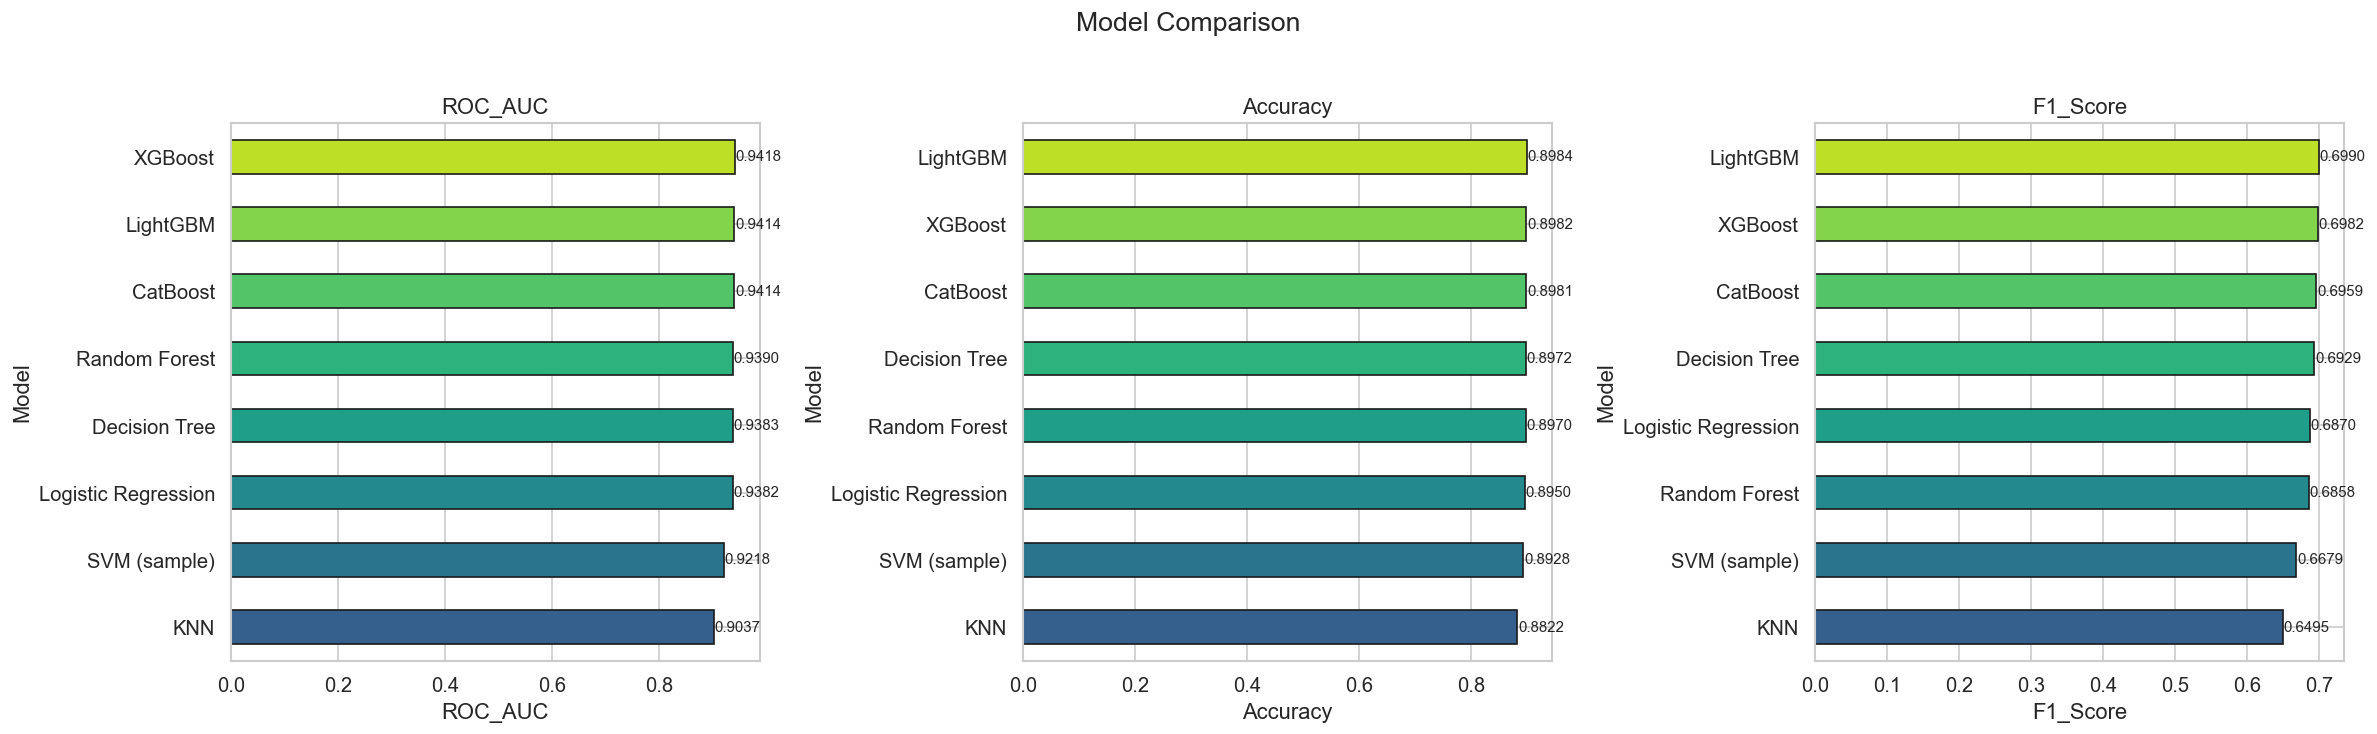

In [20]:

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, metric in enumerate(['ROC_AUC', 'Accuracy', 'F1_Score']):
    vals = results_df[metric].sort_values(ascending=True)
    colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(vals)))
    vals.plot.barh(ax=axes[i], color=colors, edgecolor='k')
    axes[i].set_title(metric)
    axes[i].set_xlabel(metric)
    # annotate
    for idx_bar, (v, name) in enumerate(zip(vals.values, vals.index)):
        axes[i].text(v + 0.001, idx_bar, f'{v:.4f}', va='center', fontsize=9)

plt.suptitle('Model Comparison', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

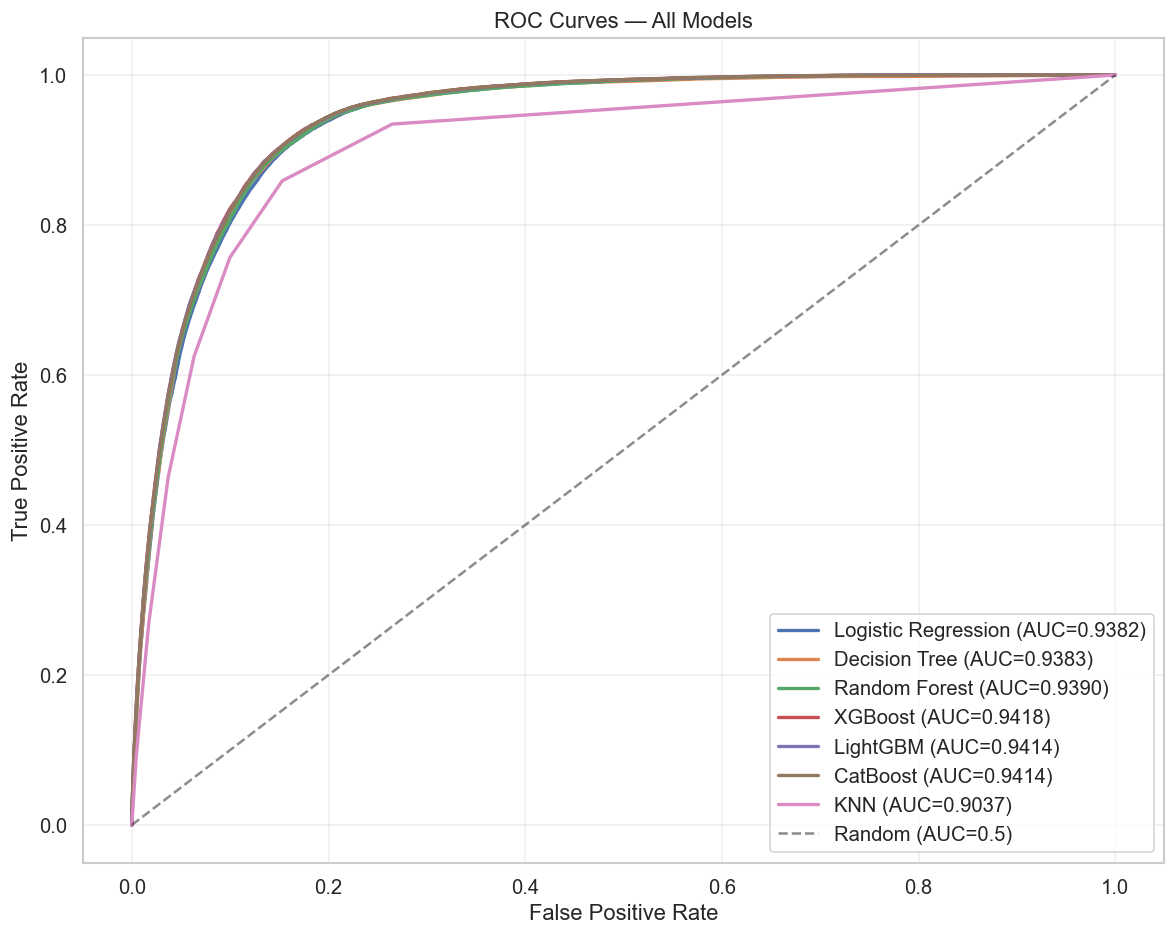

In [21]:

plt.figure(figsize=(10, 8))

models_for_roc = {
    'Logistic Regression': (lr, X_val_scaled),
    'Decision Tree': (dt, X_val),
    'Random Forest': (rf, X_val),
    'XGBoost': (xgb_clf, X_val),
    'LightGBM': (lgb_clf, X_val),
    'CatBoost': (cat_clf, X_val),
    'KNN': (knn, X_val_scaled),
}

for name, (model, X_v) in models_for_roc.items():
    y_proba = model.predict_proba(X_v)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, y_proba)
    auc_val = roc_auc_score(y_val, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc_val:.4f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC=0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All Models')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

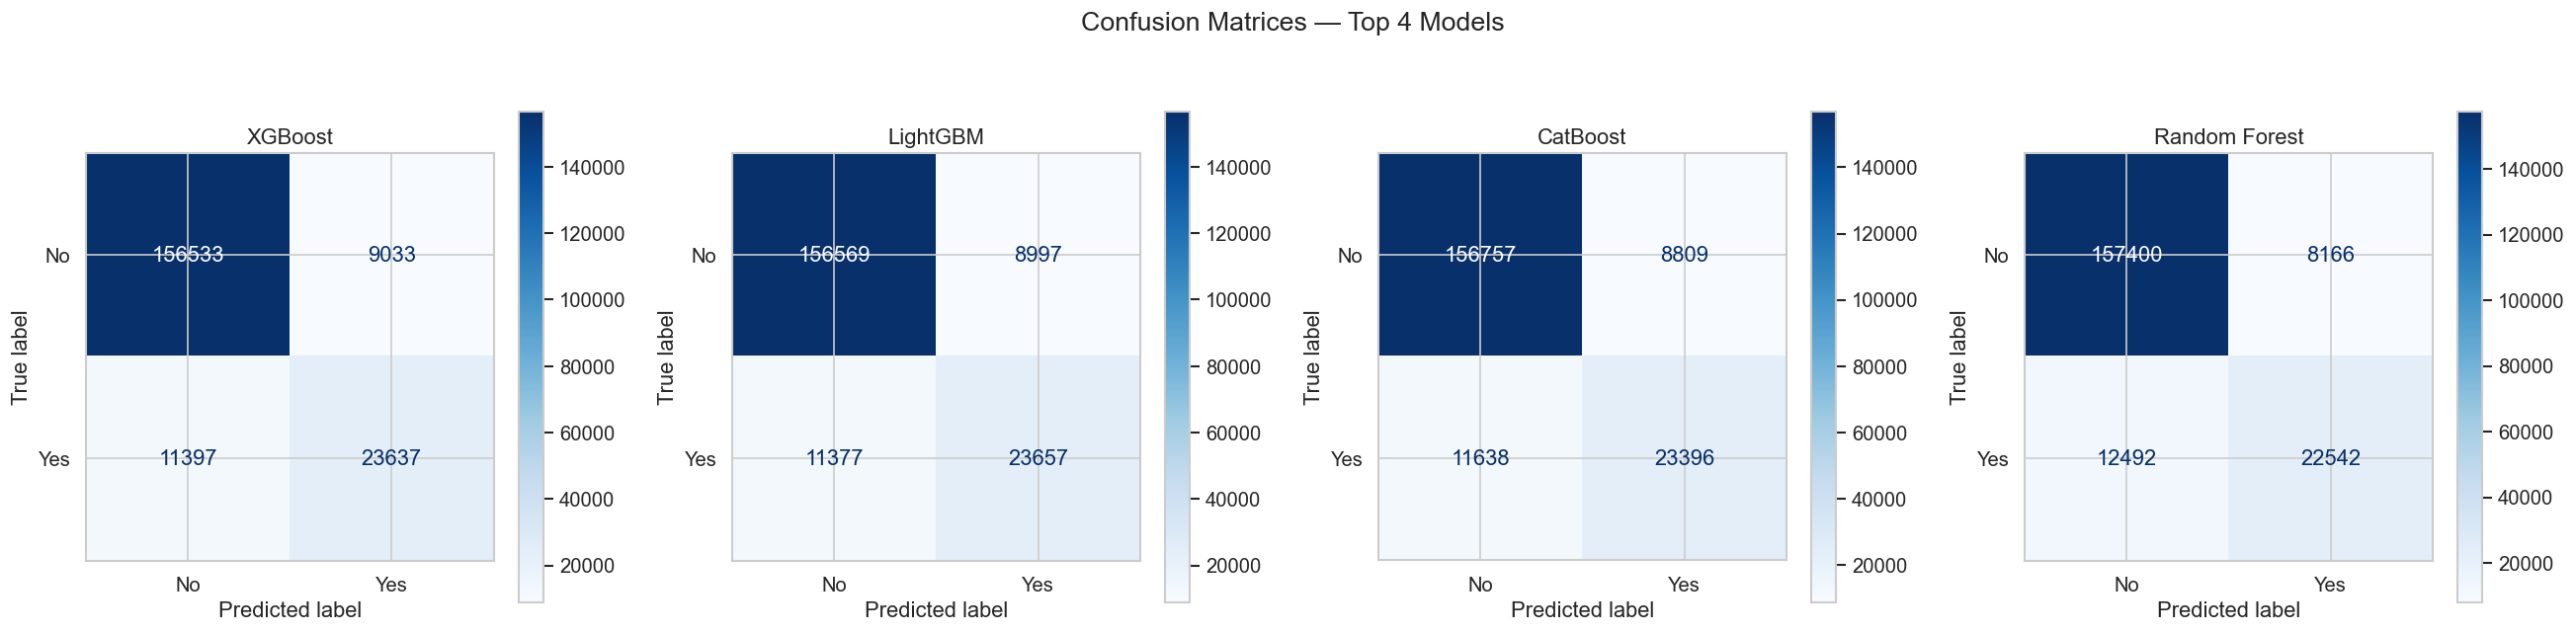

In [22]:

top4 = results_df.head(4).index.tolist()
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

all_models = {
    'Logistic Regression': (lr, X_val_scaled),
    'Decision Tree': (dt, X_val),
    'Random Forest': (rf, X_val),
    'XGBoost': (xgb_clf, X_val),
    'LightGBM': (lgb_clf, X_val),
    'CatBoost': (cat_clf, X_val),
    'KNN': (knn, X_val_scaled),
    'SVM (sample)': (svm, X_val_scaled),
}

for i, name in enumerate(top4):
    model, X_v = all_models[name]
    y_pred = model.predict(X_v)
    cm = confusion_matrix(y_val, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['No', 'Yes']).plot(ax=axes[i], cmap='Blues')
    axes[i].set_title(name)

plt.suptitle('Confusion Matrices — Top 4 Models', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

In [23]:

voting = VotingClassifier(
    estimators=[
        ('xgb', xgb.XGBClassifier(
            n_estimators=500, learning_rate=0.05, max_depth=6,
            subsample=0.8, colsample_bytree=0.8, eval_metric='auc',
            n_jobs=-1, random_state=RANDOM_STATE, use_label_encoder=False)),
        ('lgb', lgb.LGBMClassifier(
            n_estimators=500, learning_rate=0.05, num_leaves=63,
            subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)),
        ('cat', CatBoostClassifier(
            iterations=500, learning_rate=0.05, depth=6,
            verbose=0, random_state=RANDOM_STATE))
    ],
    voting='soft'
)
voting = evaluate('Voting Ensemble', voting, X_train, y_train, X_val, y_val)

  Voting Ensemble
  Accuracy : 0.8985
  ROC-AUC  : 0.9418
  F1-Score : 0.6982
  Time     : 23.22s

              precision    recall  f1-score   support

           0       0.93      0.95      0.94    165566
           1       0.73      0.67      0.70     35034

    accuracy                           0.90    200600
   macro avg       0.83      0.81      0.82    200600
weighted avg       0.90      0.90      0.90    200600



In [24]:
stack = StackingClassifier(
    estimators=[
        ('xgb', xgb.XGBClassifier(
            n_estimators=500, learning_rate=0.05, max_depth=6,
            subsample=0.8, colsample_bytree=0.8, eval_metric='auc',
            n_jobs=-1, random_state=RANDOM_STATE, use_label_encoder=False)),
        ('lgb', lgb.LGBMClassifier(
            n_estimators=500, learning_rate=0.05, num_leaves=63,
            subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)),
        ('cat', CatBoostClassifier(
            iterations=500, learning_rate=0.05, depth=6,
            verbose=0, random_state=RANDOM_STATE))
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1
)
stack = evaluate('Stacking Ensemble', stack, X_train, y_train, X_val, y_val)

  Stacking Ensemble
  Accuracy : 0.8984
  ROC-AUC  : 0.9418
  F1-Score : 0.6915
  Time     : 141.97s

              precision    recall  f1-score   support

           0       0.93      0.95      0.94    165566
           1       0.74      0.65      0.69     35034

    accuracy                           0.90    200600
   macro avg       0.83      0.80      0.82    200600
weighted avg       0.89      0.90      0.90    200600



In [25]:
# Final comparison including ensembles
results_df_final = pd.DataFrame(results).T.sort_values('ROC_AUC', ascending=False)
results_df_final.index.name = 'Model'
results_df_final.style.background_gradient(cmap='YlGn', subset=['ROC_AUC', 'F1_Score', 'Accuracy']).format({
    'Accuracy': '{:.4f}', 'ROC_AUC': '{:.4f}', 'F1_Score': '{:.4f}', 'Time_s': '{:.2f}'
})

,Accuracy,ROC_AUC,F1_Score,Time_s
Model,,,,
Voting Ensemble,0.8985,0.9418,0.6982,23.22
Stacking Ensemble,0.8984,0.9418,0.6915,141.97
XGBoost,0.8982,0.9418,0.6982,9.50
LightGBM,0.8984,0.9414,0.6990,9.09
CatBoost,0.8981,0.9414,0.6959,16.76
Random Forest,0.8970,0.9390,0.6858,30.80
Decision Tree,0.8972,0.9383,0.6929,2.14
Logistic Regression,0.8950,0.9382,0.6870,0.42
SVM (sample),0.8928,0.9218,0.6679,189.92


In [26]:

best_name = results_df_final.index[0]
print(f'\nBest : {best_name} (ROC-AUC = {results_df_final.iloc[0]["ROC_AUC"]:.4f})')

best_model_obj = joblib.load(f'models/{best_name.lower().replace(" ", "_")}.pkl')
joblib.dump(best_model_obj, 'models/best_model.pkl')
print(f'Best model saved to models/best_model.pkl')


Best : Voting Ensemble (ROC-AUC = 0.9418)
Best model saved to models/best_model.pkl


In [27]:

encoding_info = {
    'binary_cols': binary_cols,
    'range_anxiety_map': range_anxiety_map,
    'nominal_cols': ['Gender', 'City_Type', 'Current_Car_Type'],
    'feature_cols': feature_cols
}
joblib.dump(encoding_info, 'models/encoding_info.pkl')
print('Encodin saved o models/encoding_info.pkl')

Encodin saved o models/encoding_info.pkl


In [28]:

print('\n Saved in models/ directory:')
for f in sorted(os.listdir('models')):
    size = os.path.getsize(f'models/{f}') / (1024*1024)
    print(f'  {f:40s} {size:.2f} MB')


 Saved in models/ directory:
  best_model.pkl                           5.95 MB
  catboost.pkl                             0.54 MB
  decision_tree.pkl                        0.09 MB
  encoding_info.pkl                        0.00 MB
  feature_columns.pkl                      0.00 MB
  knn.pkl                                  74.99 MB
  lightgbm.pkl                             3.27 MB
  logistic_regression.pkl                  0.00 MB
  random_forest.pkl                        267.47 MB
  scaler.pkl                               0.00 MB
  stacking_ensemble.pkl                    5.95 MB
  svm_(sample).pkl                         2.16 MB
  voting_ensemble.pkl                      5.95 MB
  xgboost.pkl                              2.13 MB


In [29]:

print(f'\n5-Fold  Cross-Validation on {best_name}...')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

if best_name in ['Logistic Regression', 'KNN', 'SVM (sample)']:
    X_cv = pd.DataFrame(scaler.fit_transform(X), columns=feature_cols)
else:
    X_cv = X

cv_sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_cv), size=min(100000, len(X_cv)), replace=False)
X_cv_sample = X_cv.iloc[cv_sample_idx]
y_cv_sample = y.iloc[cv_sample_idx]

cv_scores = cross_val_score(best_model_obj, X_cv_sample, y_cv_sample, cv=cv, scoring='roc_auc', n_jobs=-1)
print(f'CV ROC-AUC scores: {cv_scores.round(4)}')
print(f'Mean: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')


5-Fold  Cross-Validation on Voting Ensemble...
CV ROC-AUC scores: [0.9405 0.9403 0.9393 0.9413 0.9401]
Mean: 0.9403 ± 0.0006
